<a href="https://colab.research.google.com/github/leman973/Deep-Learning/blob/main/Pract_1_DL_clg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np

In [3]:
import pandas as pd
import tensorflow as tf

In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input

In [5]:
train_df = pd.read_csv("sign_mnist_train.csv")
test_df = pd.read_csv("sign_mnist_test.csv")

In [6]:
y_train = train_df["label"].values
x_train = train_df.drop("label",axis=1).values

In [7]:
y_test = test_df["label"].values
x_test = test_df.drop("label",axis = 1).values

In [8]:
x_train

array([[107., 118., 127., ..., 204., 203., 202.],
       [155., 157., 156., ..., 103., 135., 149.],
       [187., 188., 188., ..., 195., 194., 195.],
       ...,
       [171., 174., 178., ...,  43.,  28.,  28.],
       [110., 117., 122., ..., 179., 177., 182.],
       [176., 178., 182., ...,  nan,  nan,  nan]], shape=(5527, 784))

In [9]:
x_train = x_train.reshape(-1,28,28)
x_test = x_test.reshape(-1,28,28)

In [10]:
x_train

array([[[107., 118., 127., ..., 170., 170., 169.],
        [111., 121., 129., ..., 171., 171., 170.],
        [113., 123., 131., ..., 171., 171., 171.],
        ...,
        [142., 150., 159., ..., 202., 201., 200.],
        [142., 151., 160., ..., 204., 203., 202.],
        [142., 151., 160., ..., 204., 203., 202.]],

       [[155., 157., 156., ..., 138.,  92., 108.],
        [158., 159., 159., ..., 142., 116., 143.],
        [161., 161., 161., ..., 147., 125., 140.],
        ...,
        [162., 159., 145., ...,  91., 101.,  94.],
        [153., 139., 115., ...,  97.,  95., 120.],
        [135., 116.,  95., ..., 103., 135., 149.]],

       [[187., 188., 188., ...,  66.,  77.,  83.],
        [188., 189., 189., ...,  73.,  73.,  71.],
        [190., 190., 190., ...,  74.,  68.,  61.],
        ...,
        [212., 198., 175., ..., 195., 193., 192.],
        [202., 179., 152., ..., 195., 194., 193.],
        [198., 166., 132., ..., 195., 194., 195.]],

       ...,

       [[171., 174., 178

In [11]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [12]:
x_train

array([[[0.41960784, 0.4627451 , 0.49803922, ..., 0.66666667,
         0.66666667, 0.6627451 ],
        [0.43529412, 0.4745098 , 0.50588235, ..., 0.67058824,
         0.67058824, 0.66666667],
        [0.44313725, 0.48235294, 0.51372549, ..., 0.67058824,
         0.67058824, 0.67058824],
        ...,
        [0.55686275, 0.58823529, 0.62352941, ..., 0.79215686,
         0.78823529, 0.78431373],
        [0.55686275, 0.59215686, 0.62745098, ..., 0.8       ,
         0.79607843, 0.79215686],
        [0.55686275, 0.59215686, 0.62745098, ..., 0.8       ,
         0.79607843, 0.79215686]],

       [[0.60784314, 0.61568627, 0.61176471, ..., 0.54117647,
         0.36078431, 0.42352941],
        [0.61960784, 0.62352941, 0.62352941, ..., 0.55686275,
         0.45490196, 0.56078431],
        [0.63137255, 0.63137255, 0.63137255, ..., 0.57647059,
         0.49019608, 0.54901961],
        ...,
        [0.63529412, 0.62352941, 0.56862745, ..., 0.35686275,
         0.39607843, 0.36862745],
        [0.6

In [13]:
print("Training Data Shape", x_train.shape)

Training Data Shape (5527, 28, 28)


In [14]:
print("Testing Data Shape", x_test.shape)

Testing Data Shape (7172, 28, 28)


In [15]:
model = Sequential([
    Input(shape=(28,28)),
    Flatten(),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(25, activation="softmax")
])

In [16]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics = ["accuracy"])

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,361 (431.10 KB)

 Trainable params: 110,361 (431.10 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
history = model.fit(
    x_train, y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.1070 - loss: 3.0527 - val_accuracy: 0.1718 - val_loss: nan
Epoch 2/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2545 - loss: 2.5582 - val_accuracy: 0.2495 - val_loss: nan
Epoch 3/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3440 - loss: 2.1448 - val_accuracy: 0.3870 - val_loss: nan
Epoch 4/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4254 - loss: 1.8591 - val_accuracy: 0.4358 - val_loss: nan
Epoch 5/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.4988 - loss: 1.6562 - val_accuracy: 0.4575 - val_loss: nan
Epoch 6/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5253 - loss: 1.5236 - val_accuracy: 0.5172 - val_loss: nan
Epoch 7/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5669 - loss: 1.4170 - val_accuracy: 0.4919 - val_loss: nan
Epoch 8/15
78/78 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5867 - loss: 1.3324 - val_accuracy: 0.5389 - val_loss: nan
Epoch 9/15
78/78

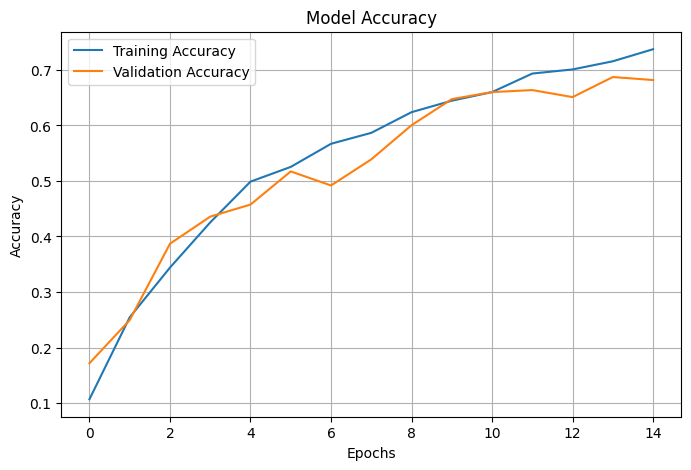

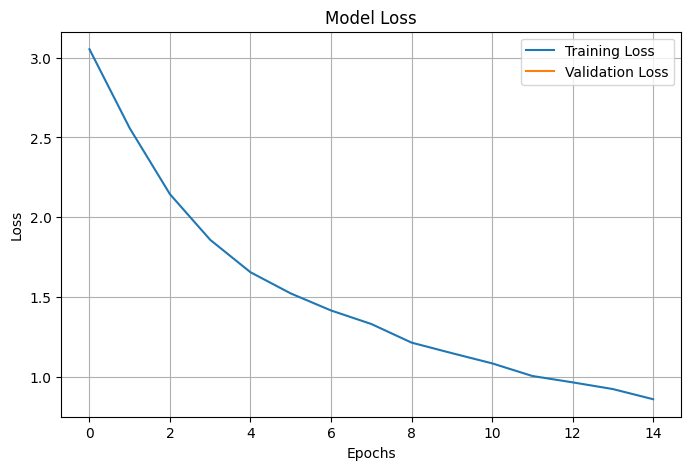

In [19]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

In [20]:
test_loss, test_acc = model.evaluate(x_test,y_test)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6014 - loss: 1.3368


In [21]:
history.history["accuracy"]

[0.10695616900920868,
 0.25452351570129395,
 0.3439887464046478,
 0.4254121482372284,
 0.49879372119903564,
 0.5253317356109619,
 0.5669481158256531,
 0.5866506099700928,
 0.6238439679145813,
 0.644551694393158,
 0.6600321531295776,
 0.6934056878089905,
 0.700844407081604,
 0.7155206799507141,
 0.7372336387634277]

In [22]:
train_loss, train_accuracy = model.evaluate(x_train, y_train)

173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7196 - loss: nan   


225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


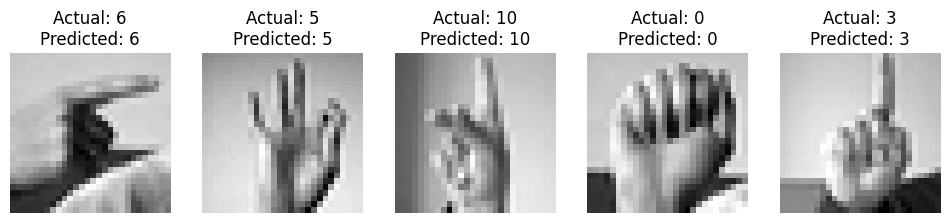

In [23]:
import matplotlib.pyplot as plt

predicted = model.predict(x_test)
predictions = np.argmax(predicted, axis=1)

plt.figure(figsize=(12,5))
for i in range(5):
  plt.subplot(1,5,i+1)
  plt.imshow(x_test[i].reshape(28,28), cmap="gray")
  plt.title(
      f"Actual: {y_test[i]}\nPredicted: {predictions[i]}"
  )
  plt.axis("off")
plt.show()

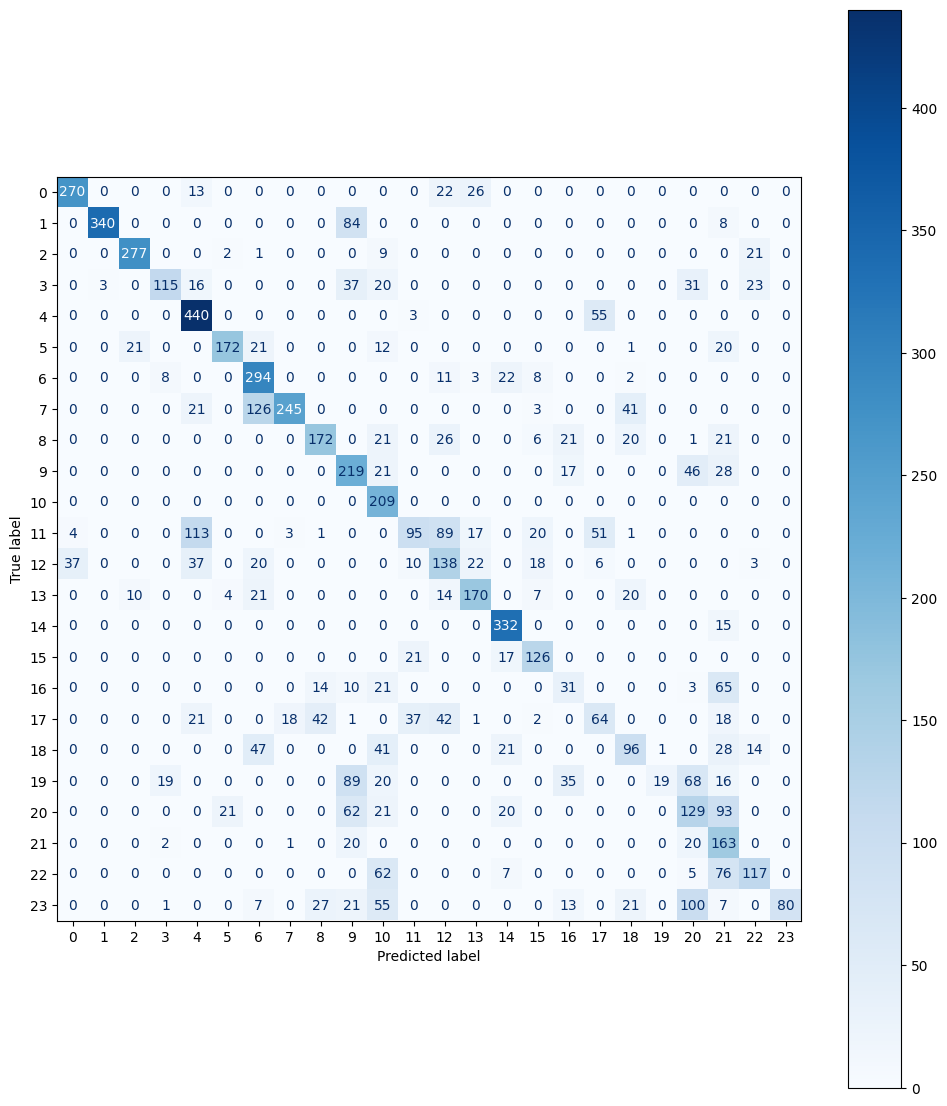

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

plt.figure(figsize=(12,14))
cm = confusion_matrix(y_test, predictions)
dis = ConfusionMatrixDisplay(cm)
dis.plot(cmap="Blues",ax=plt.gca())
plt.show()